# Q5 - Active vs inactive players: comparison of the features

Which player features differ between players still active and players who left?

Choices:
- Source: `player_features.parquet` (notebook 04), one row per player.
- Rate-based features (win rate, K/D, ratios, scores) are noisy with few matches: plots use players with **10+ matches** (`MIN_MATCHES_PLOT`), as in the previous notebooks. The summary of section 1 is given for all players and for 10+ matches.
- The recency features (`days_since_last_match`, `matches_last_30d`, `matches_last_90d`) almost define inactivity: they are left out of the comparison.
- Effect size = **AUC** of the feature to tell an active from an inactive player (0.5 = no difference, 1 = active players always higher, 0 = always lower), with a Mann-Whitney test.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from scipy.stats import mannwhitneyu

sns.set_theme(style='whitegrid')

FEATURES_PATH: Path = Path('player_features.parquet')
MIN_MATCHES_PLOT: int = 10
LEAKING: list[str] = ['last_match', 'days_since_last_match', 'matches_last_30d', 'matches_last_90d']
HUE_ORDER: list[str] = ['Active', 'Inactive']

df_players: pl.DataFrame = pl.read_parquet(FEATURES_PATH).with_columns(
    pl.when(pl.col('still_active')).then(pl.lit('Active')).otherwise(pl.lit('Inactive')).alias('activity'),
    pl.col('last_result_win').cast(pl.Float64),
)
df_players_10: pl.DataFrame = df_players.filter(pl.col('matches') >= MIN_MATCHES_PLOT)
print(df_players.shape, '| 10+ matches:', df_players_10.height)
df_players.group_by('activity').agg(
    pl.len().alias('players'),
    pl.col('matches').median().alias('matches_median'),
    (pl.col('matches') >= MIN_MATCHES_PLOT).sum().alias('players_10plus'),
).sort('activity')

FileNotFoundError: Le fichier spécifié est introuvable. (os error 2): player_features.parquet

This error occurred with the following context stack:
	[1] 'parquet scan'
	[2] 'sink'


## 1. Summary: every feature, active vs inactive

In [ ]:
FEATURES: list[str] = [
    c for c, t in df_players.schema.items()
    if (t.is_numeric() or t == pl.Boolean) and c not in LEAKING and c != 'still_active'
]


def compare(df: pl.DataFrame, features: list[str]) -> pl.DataFrame:
    rows = []
    for feature in features:
        active = df.filter(pl.col('still_active'))[feature].drop_nulls().to_numpy().astype(float)
        inactive = df.filter(~pl.col('still_active'))[feature].drop_nulls().to_numpy().astype(float)
        if len(active) < 5 or len(inactive) < 5:
            continue
        u, p = mannwhitneyu(active, inactive)
        rows.append({
            'feature': feature, 'n_active': len(active), 'n_inactive': len(inactive),
            'median_active': float(np.median(active)), 'median_inactive': float(np.median(inactive)),
            'auc': float(u / (len(active) * len(inactive))), 'p_value': float(p),
        })
    return pl.DataFrame(rows).with_columns((pl.col('auc') - 0.5).abs().alias('effect')).sort('effect', descending=True)


df_cmp_all: pl.DataFrame = compare(df_players, FEATURES)
df_cmp_10: pl.DataFrame = compare(df_players_10, FEATURES)
print('all players: features with p < 0.01:', df_cmp_all.filter(pl.col('p_value') < 0.01).height, 'of', df_cmp_all.height)
print('10+ matches: features with p < 0.01:', df_cmp_10.filter(pl.col('p_value') < 0.01).height, 'of', df_cmp_10.height)
df_cmp_10.select(
    'feature', 'n_active', 'n_inactive', pl.col('median_active').round(3), pl.col('median_inactive').round(3), pl.col('auc').round(3), pl.col('p_value').round(4),
).head(25)

all players: features with p < 0.01: 45 of 65
10+ matches: features with p < 0.01: 27 of 65


feature,n_active,n_inactive,median_active,median_inactive,auc,p_value
str,i64,i64,f64,f64,f64,f64
"""tenure_days""",303,240,250.339,81.495,0.73,0.0
"""active_days""",303,240,30.0,12.0,0.718,0.0
"""active_weeks""",303,240,12.0,5.0,0.716,0.0
"""sessions""",303,240,60.0,21.0,0.711,0.0
"""unique_opponents""",303,240,585.0,249.0,0.69,0.0
…,…,…,…,…,…,…
"""share_pvp_ranked""",303,240,0.4,0.031,0.609,0.0
"""elo_low""",303,240,930.611,898.591,0.606,0.0
"""share_night""",303,240,0.312,0.156,0.596,0.0001


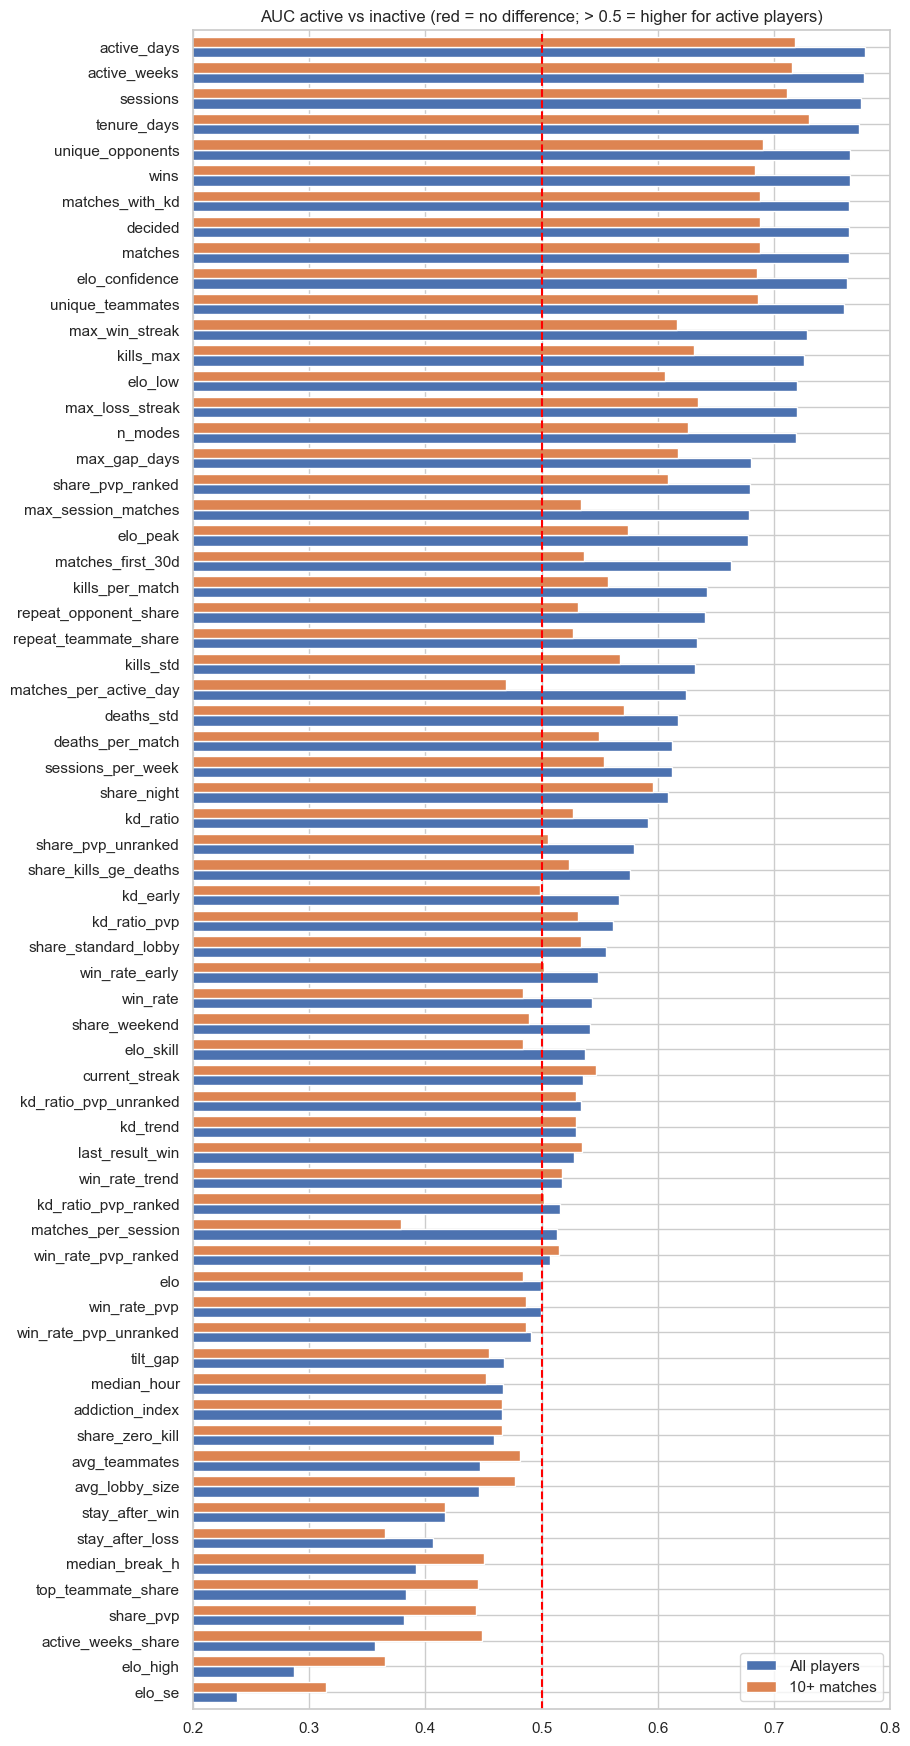

In [ ]:
# AUC per feature, all players vs 10+ matches
df_auc = (
    df_cmp_all.select('feature', pl.col('auc').alias('All players'))
    .join(df_cmp_10.select('feature', pl.col('auc').alias(f'{MIN_MATCHES_PLOT}+ matches')), on='feature', how='left')
    .sort('All players')
)
fig, ax = plt.subplots(figsize=(9, 0.32 * df_auc.height + 1))
df_auc.to_pandas().set_index('feature').plot.barh(ax=ax, width=0.8)
ax.axvline(0.5, color='red', linestyle='--')
ax.set_xlim(0.2, 0.8)
ax.set_title('AUC active vs inactive (red = no difference; > 0.5 = higher for active players)')
ax.set_ylabel('')
plt.show()

Observation:
- 352 active vs 488 inactive players; **half of the inactive players have fewer than 10 matches** (median 9 vs 88.5 for active ones): most churn happens at the very beginning.
- 45 of 65 features differ (p < 0.01) over all players, only 27 with 10+ matches: much of the gap comes from the one-time players.
- Biggest gaps are lifespan / volume (`tenure_days` AUC 0.73: median 250 vs 81 days), partly a consequence of staying.

In [ ]:
def split_violins(features: list[str], log: tuple[str, ...] = (), ncols: int = 3, reference: dict[str, float] | None = None) -> None:
    # one split violin per feature: Active (left) vs Inactive (right), players with 10+ matches
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows))
    axes = np.ravel(axes)
    pdf = df_players_10.to_pandas()
    pdf['all'] = ''
    for i, (ax, feature) in enumerate(zip(axes, features)):
        data = pdf.dropna(subset=[feature])
        if feature in log:
            data = data[data[feature] > 0]
        sns.violinplot(
            data=data, x='all', y=feature, hue='activity', hue_order=HUE_ORDER, split=True, inner='quartile', cut=0,
            density_norm='width', gap=0.05, log_scale=feature in log, ax=ax,
        )
        if reference and feature in reference:
            ax.axhline(reference[feature], color='red', linestyle='--')
        ax.set_xlabel('')
        ax.set_title(feature + (' (log)' if feature in log else ''))
        if i == 0:
            ax.legend(title='')
        else:
            ax.get_legend().remove()
    for ax in axes[len(features):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()


def summary(features: list[str]) -> pl.DataFrame:
    return df_cmp_10.filter(pl.col('feature').is_in(features)).select(
        'feature', 'n_active', 'n_inactive', pl.col('median_active').round(3), pl.col('median_inactive').round(3), pl.col('auc').round(3), pl.col('p_value').round(4),
    ).sort('feature')

## 2. Activity and tenure (10+ matches)

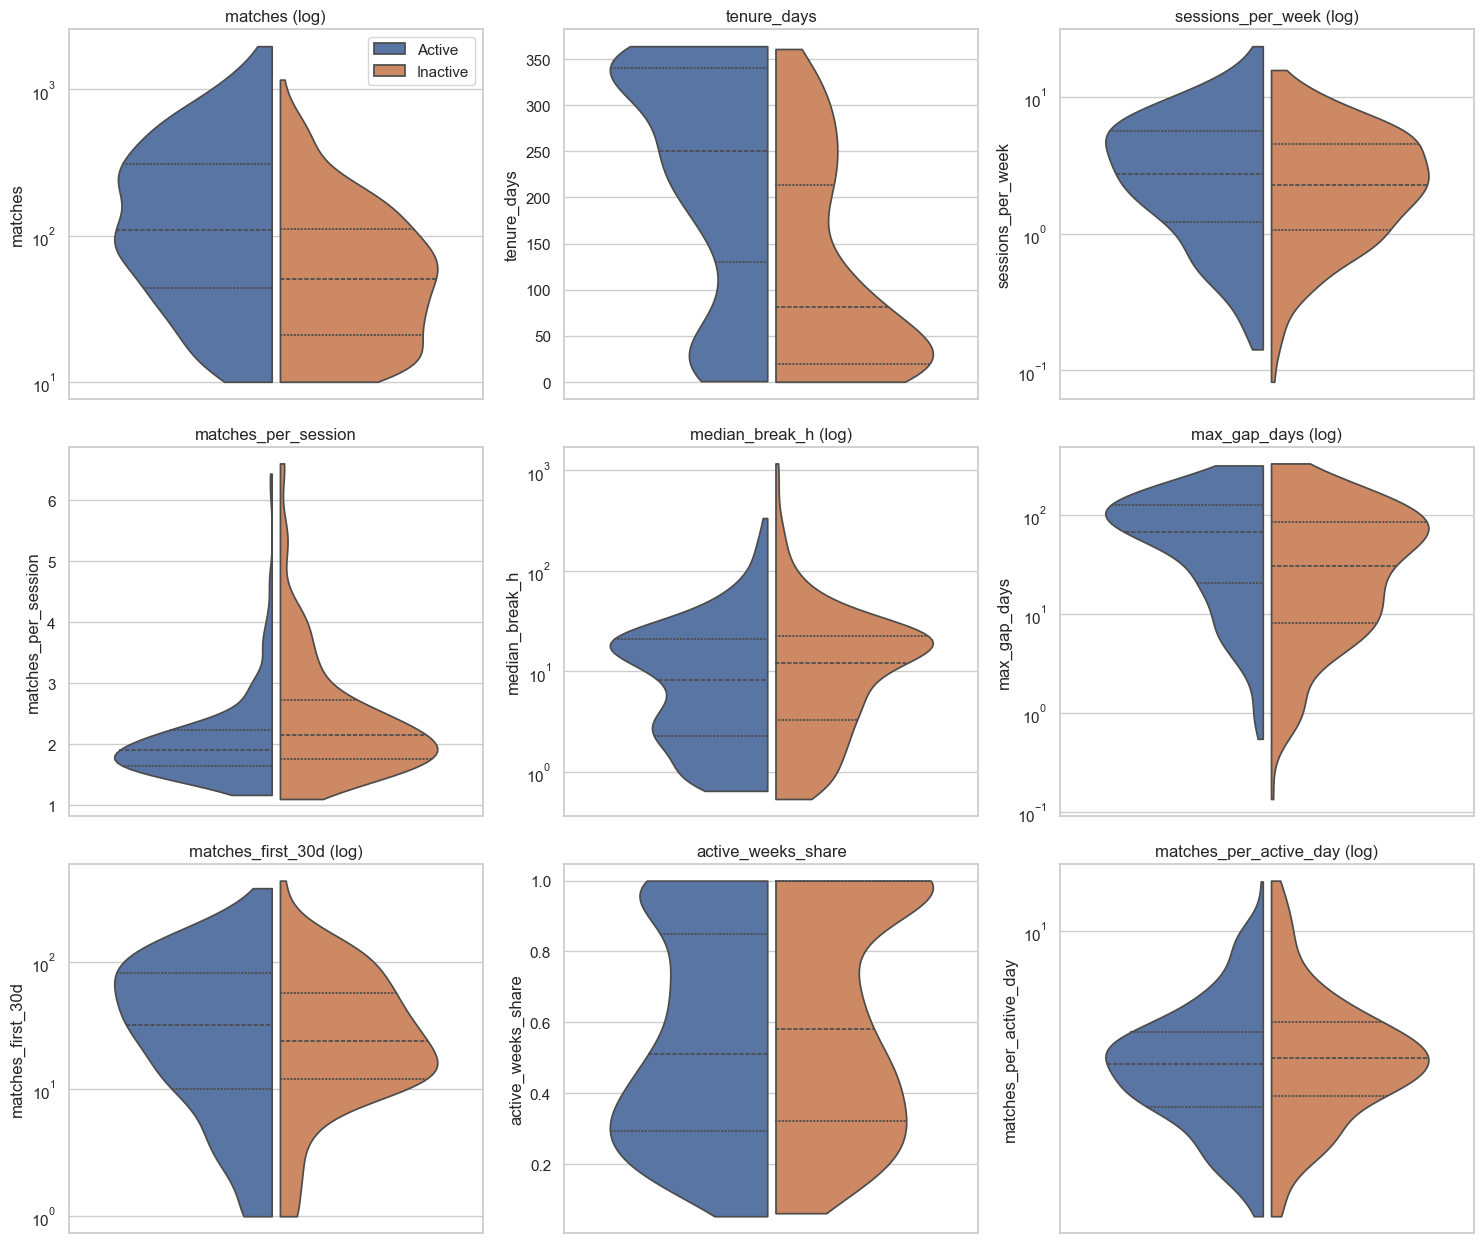

feature,n_active,n_inactive,median_active,median_inactive,auc,p_value
str,i64,i64,f64,f64,f64,f64
"""active_weeks_share""",303,240,0.511,0.58,0.448,0.0378
"""matches""",303,240,110.0,50.5,0.688,0.0
"""matches_first_30d""",303,240,32.0,24.0,0.537,0.1403
"""matches_per_active_day""",303,240,4.031,4.189,0.469,0.2166
"""matches_per_session""",303,240,1.899,2.155,0.379,0.0
"""max_gap_days""",303,240,66.611,30.491,0.618,0.0
"""median_break_h""",303,240,8.173,12.011,0.451,0.0486
"""sessions_per_week""",303,240,2.741,2.284,0.554,0.0309
"""tenure_days""",303,240,250.339,81.495,0.73,0.0


In [ ]:
ACTIVITY = ['matches', 'tenure_days', 'sessions_per_week', 'matches_per_session', 'median_break_h', 'max_gap_days', 'matches_first_30d', 'active_weeks_share', 'matches_per_active_day']
split_violins(ACTIVITY, log=('matches', 'median_break_h', 'max_gap_days', 'matches_first_30d', 'sessions_per_week', 'matches_per_active_day'))
summary(ACTIVITY)

Observation:
- Active players have more matches (median 110 vs 50.5) over a longer lifespan, but the same pace: 2.7 vs 2.3 sessions per week.
- Inactive players play slightly longer sessions (2.16 vs 1.90 matches per session) with shorter breaks (median 8.2 h active vs 12.0 h inactive): **a short and dense period, then they leave**.
- Longest gap is larger for active players (66 vs 30 days): they pause and come back.
- Matches in the first 30 days do not differ (32 vs 24, p = 0.14).

## 3. Performance (10+ matches)

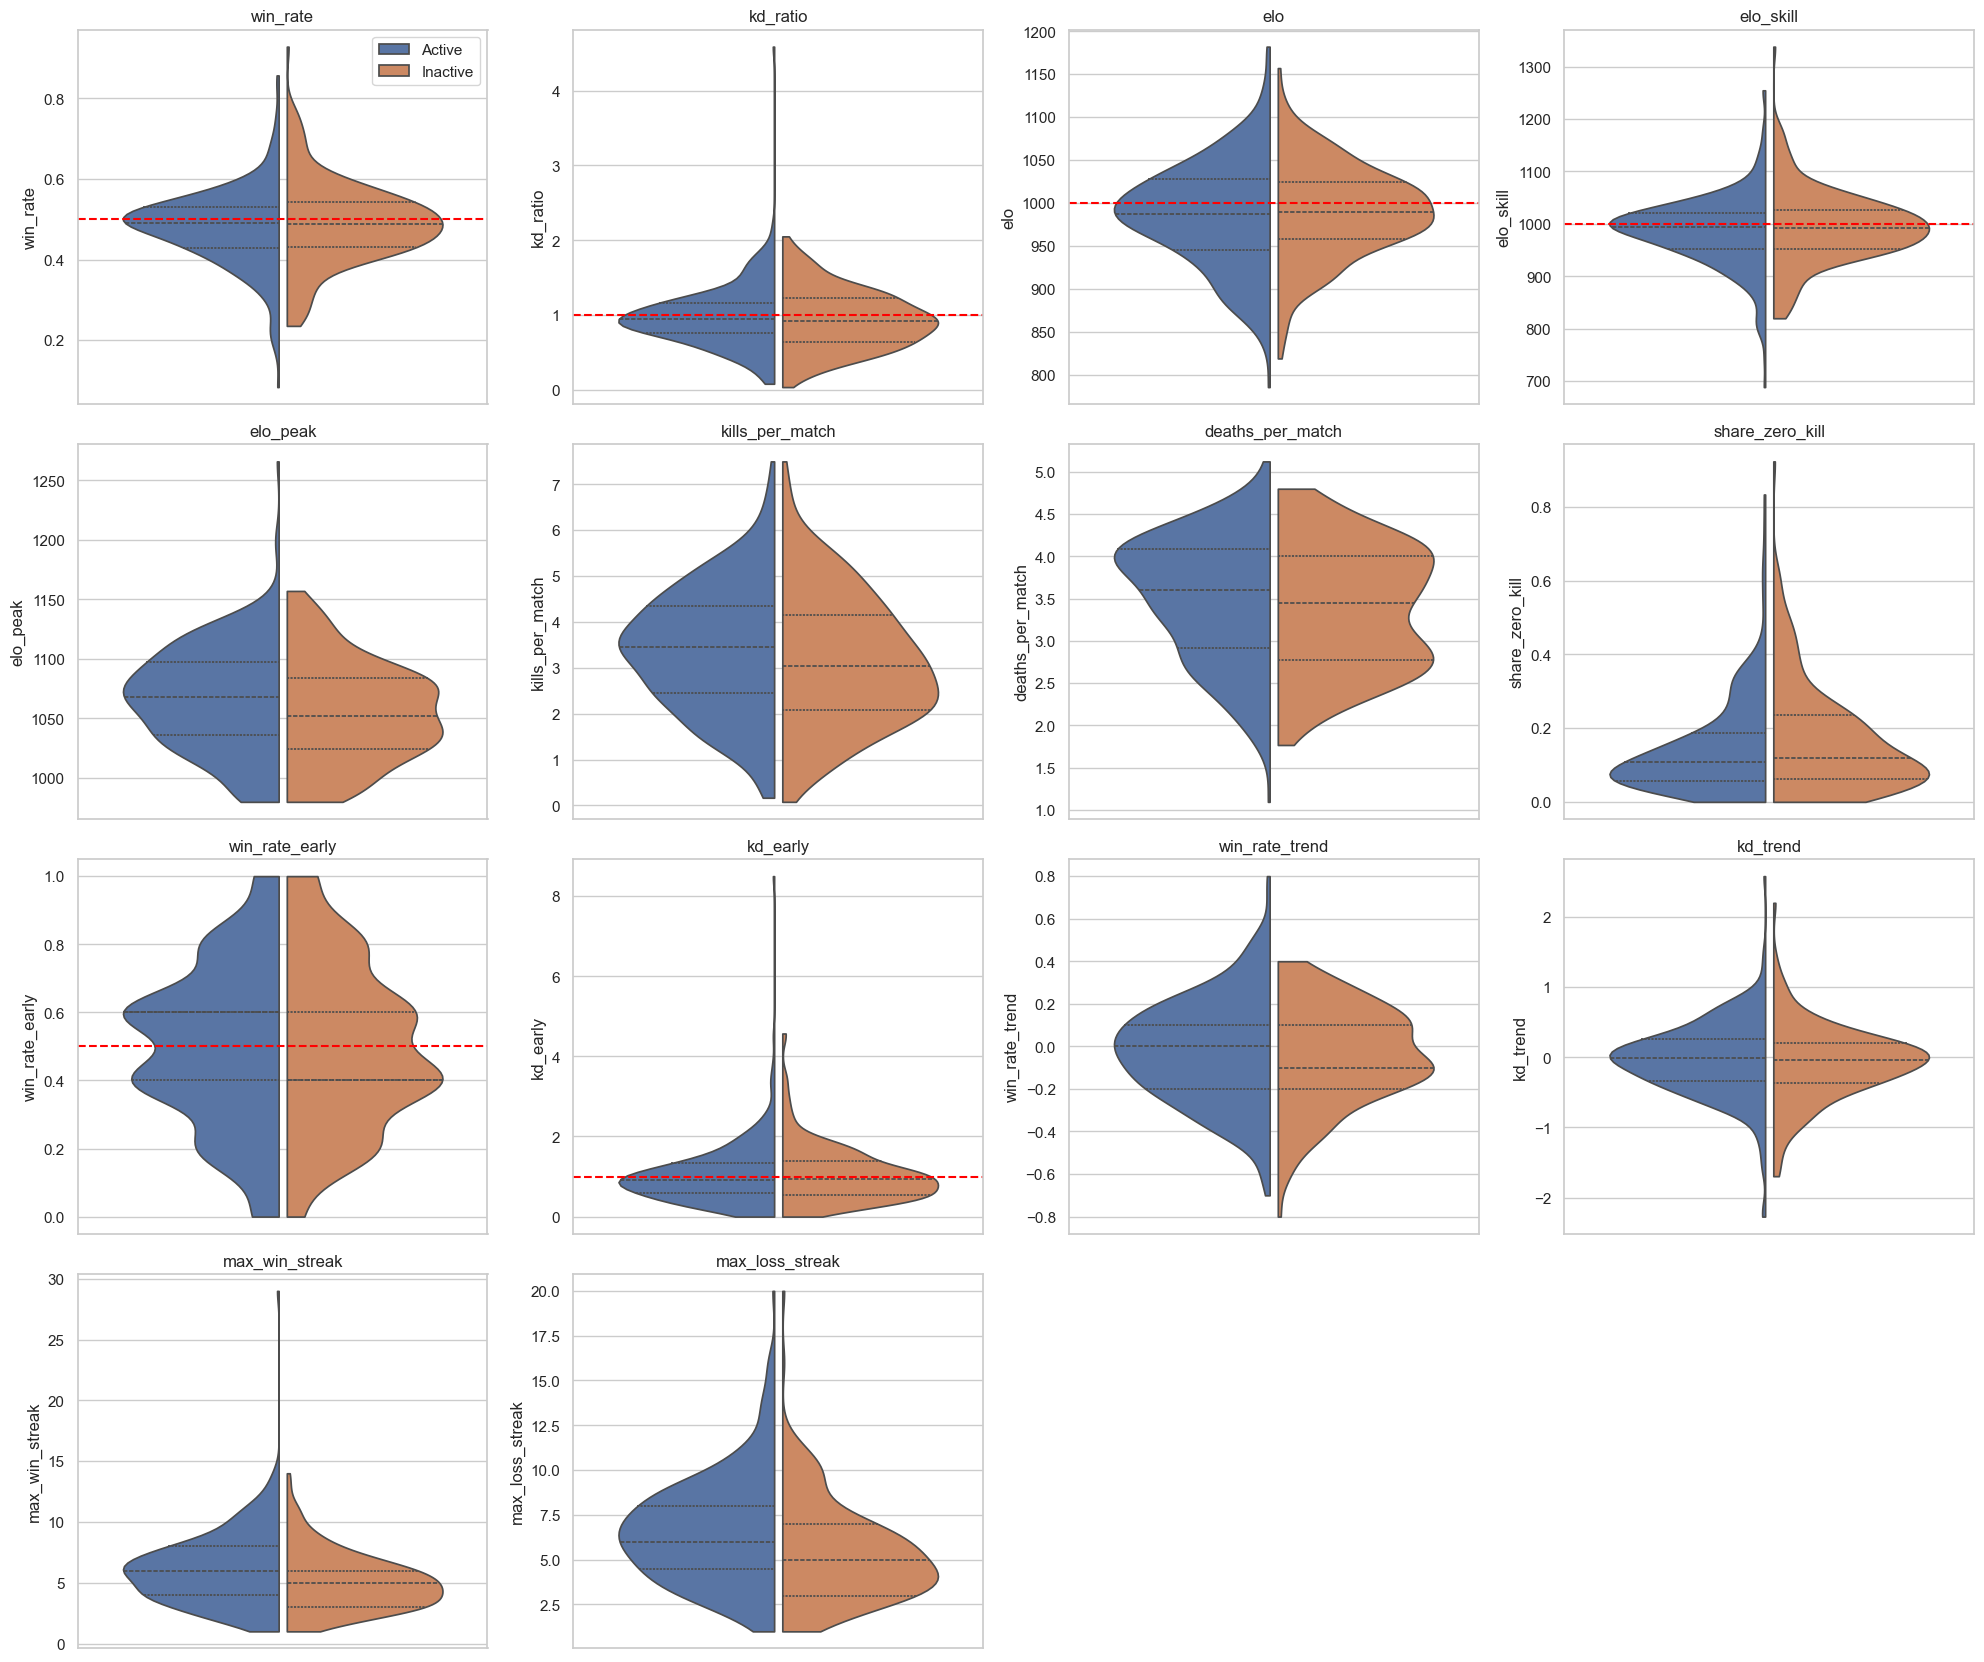

feature,n_active,n_inactive,median_active,median_inactive,auc,p_value
str,i64,i64,f64,f64,f64,f64
"""deaths_per_match""",303,240,3.606,3.452,0.55,0.0466
"""elo""",303,240,987.686,989.947,0.484,0.5213
"""elo_peak""",303,240,1068.252,1052.43,0.575,0.0028
"""elo_skill""",303,240,993.318,992.704,0.484,0.5157
"""kd_early""",303,240,0.917,0.939,0.499,0.9541
…,…,…,…,…,…,…
"""max_win_streak""",303,240,6.0,5.0,0.617,0.0
"""share_zero_kill""",303,240,0.108,0.12,0.466,0.175
"""win_rate""",303,240,0.49,0.489,0.484,0.5148


In [ ]:
PERFORMANCE = ['win_rate', 'kd_ratio', 'elo', 'elo_skill', 'elo_peak', 'kills_per_match', 'deaths_per_match', 'share_zero_kill', 'win_rate_early', 'kd_early', 'win_rate_trend', 'kd_trend', 'max_win_streak', 'max_loss_streak']
split_violins(PERFORMANCE, reference={'win_rate': 0.5, 'kd_ratio': 1, 'elo': 1000, 'elo_skill': 1000, 'win_rate_early': 0.5, 'kd_early': 1}, ncols=4)
summary(PERFORMANCE)

Observation:
- **Identical skill** in both groups: win rate 49.0% vs 48.9%, K/D 0.95 vs 0.92, Elo 988 vs 990 and Elo skill 993 vs 993 (p > 0.2), same early win rate / K/D and trend: players do not leave because they lose.
- Only `elo_peak` (1068 vs 1052) and `max_win_streak` (6 vs 5) are higher for active players: more matches, more chances to reach a peak.
- Active players have slightly more kills per match (3.46 vs 3.04) with the same K/D.

## 4. Behaviour and addiction index (10+ matches)

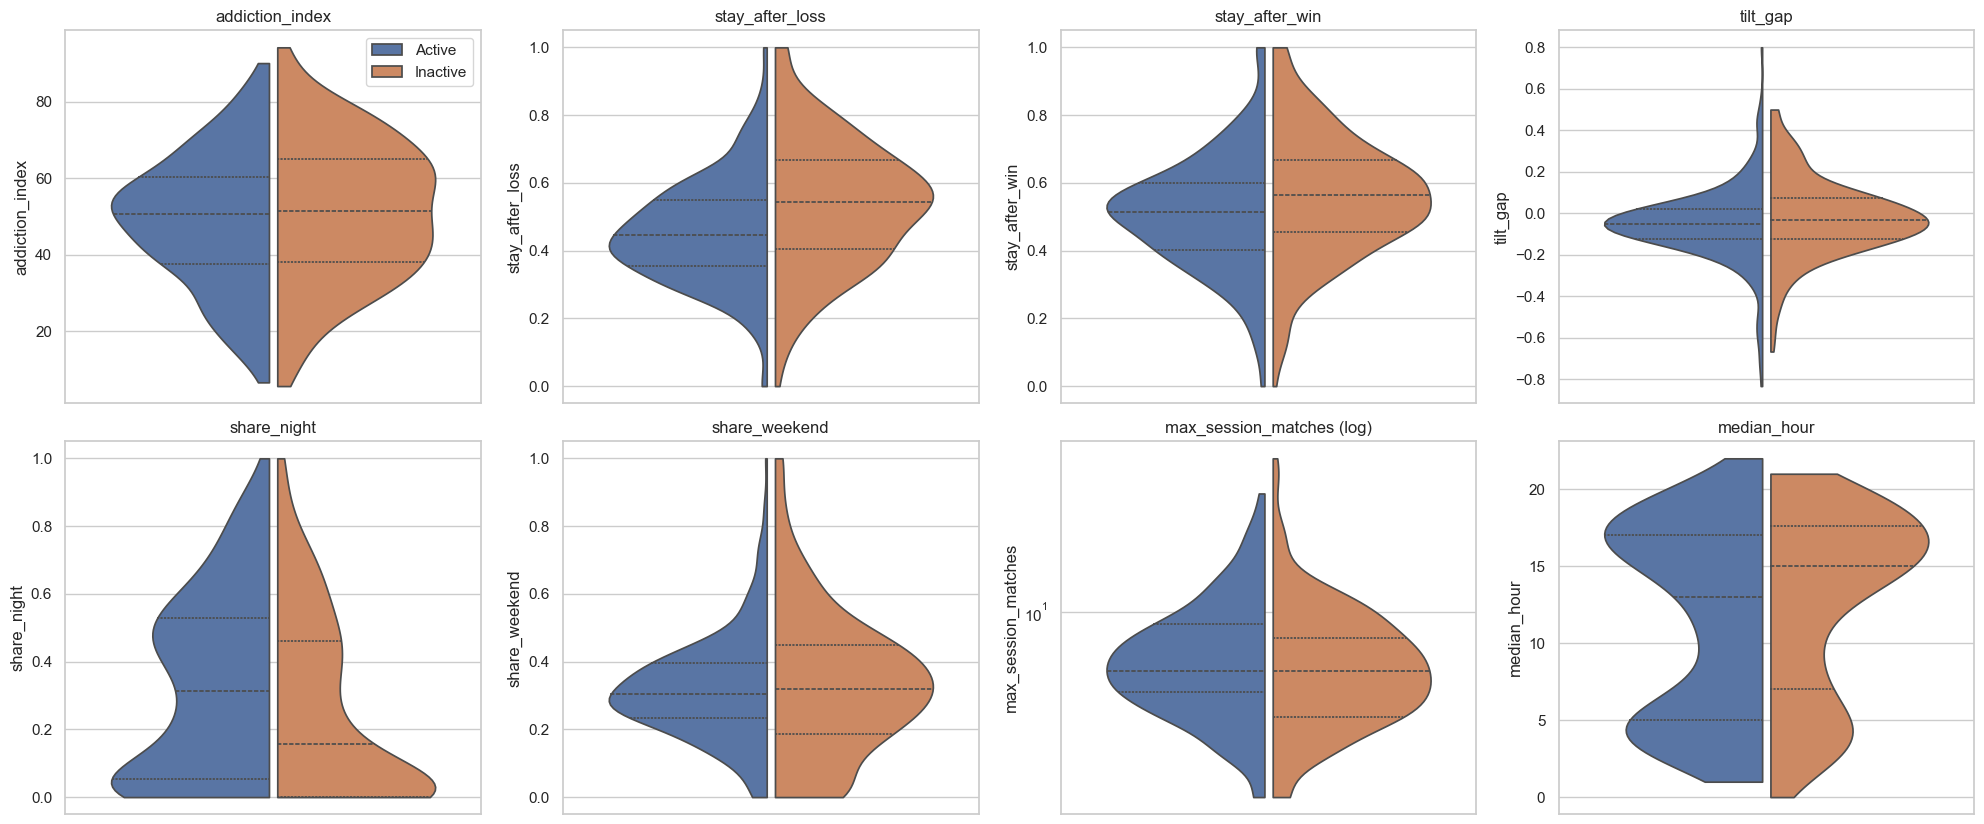

feature,n_active,n_inactive,median_active,median_inactive,auc,p_value
str,i64,i64,f64,f64,f64,f64
"""addiction_index""",303,240,50.605,51.592,0.466,0.1748
"""max_session_matches""",303,240,6.0,6.0,0.534,0.1729
"""median_hour""",303,240,13.0,15.0,0.452,0.0543
"""share_night""",303,240,0.312,0.156,0.596,0.0001
"""share_weekend""",303,240,0.303,0.318,0.489,0.6671
"""stay_after_loss""",303,240,0.446,0.542,0.366,0.0
"""stay_after_win""",303,240,0.513,0.565,0.417,0.0008
"""tilt_gap""",303,240,-0.051,-0.033,0.455,0.0728


In [ ]:
BEHAVIOUR = ['addiction_index', 'stay_after_loss', 'stay_after_win', 'tilt_gap', 'share_night', 'share_weekend', 'max_session_matches', 'median_hour']
split_violins(BEHAVIOUR, log=('max_session_matches',), ncols=4)
summary(BEHAVIOUR)

Observation:
- Same addiction index (median 50.6 vs 51.6, p = 0.17): **intensity of play does not protect from churn**.
- Inactive players requeue more after a loss (54% vs 45%) and after a win (57% vs 51%).
- Active players play more at night in UTC (31% vs 16% of their matches): a schedule / region effect more than a behaviour (time zone unknown).
- No difference for weekend play and longest session (6 matches).

## 5. Game modes and social (10+ matches)

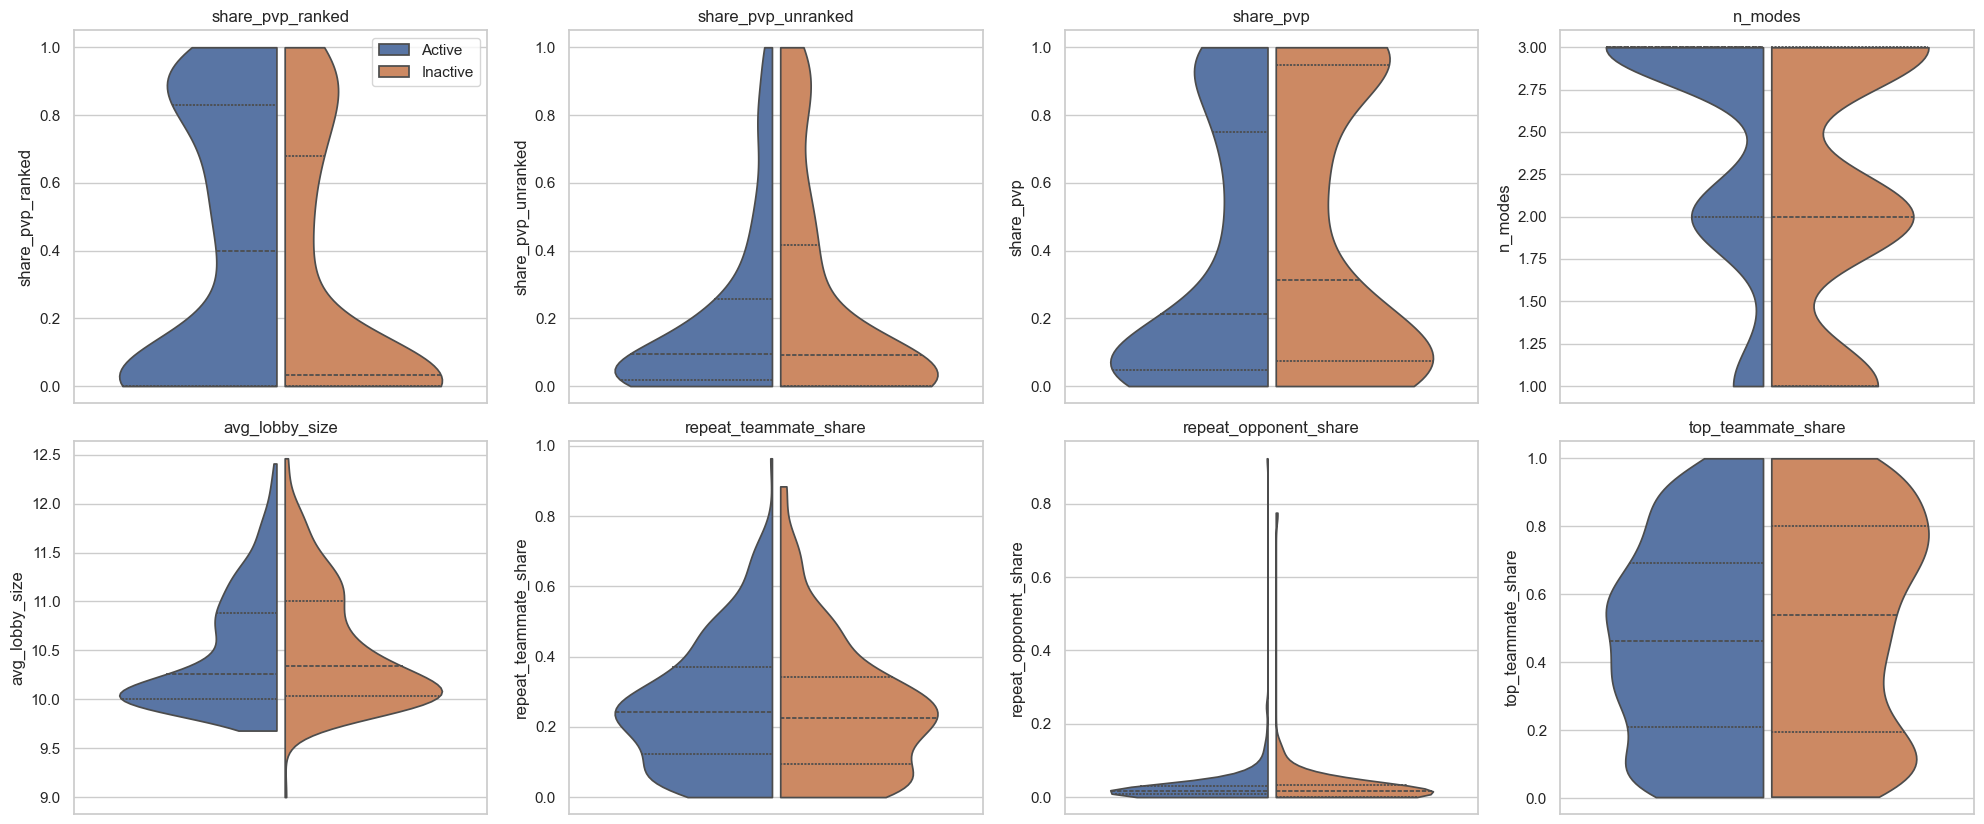

feature,n_active,n_inactive,median_active,median_inactive,auc,p_value
str,i64,i64,f64,f64,f64,f64
"""avg_lobby_size""",303,240,10.257,10.336,0.477,0.358
"""n_modes""",303,240,3.0,2.0,0.626,0.0
"""repeat_opponent_share""",303,240,0.016,0.016,0.531,0.2088
"""repeat_teammate_share""",303,240,0.243,0.226,0.527,0.2839
"""share_pvp""",303,240,0.213,0.312,0.444,0.0237
"""share_pvp_ranked""",303,240,0.4,0.031,0.609,0.0
"""share_pvp_unranked""",303,240,0.095,0.092,0.505,0.8321
"""top_teammate_share""",303,240,0.462,0.539,0.445,0.0274


In [ ]:
MODES_SOCIAL = ['share_pvp_ranked', 'share_pvp_unranked', 'share_pvp', 'n_modes', 'avg_lobby_size', 'repeat_teammate_share', 'repeat_opponent_share', 'top_teammate_share']
split_violins(MODES_SOCIAL, ncols=4)
summary(MODES_SOCIAL)

Observation:
- `PVP_RANKED` is the clearest mode signal: median share of 40% for active players vs 3% for inactive ones (AUC 0.61), and they play more modes (3 vs 2, AUC 0.63). Inactive players lean on `PVP` (31% vs 21%).
- Lobby size and repeat teammates / opponents are similar; inactive players have a slightly higher top teammate share (54% vs 46%, p = 0.03).

## 6. Active vs inactive by main game mode (10+ matches)

Same split as notebook 03: a player is assigned to the mode where he plays most.

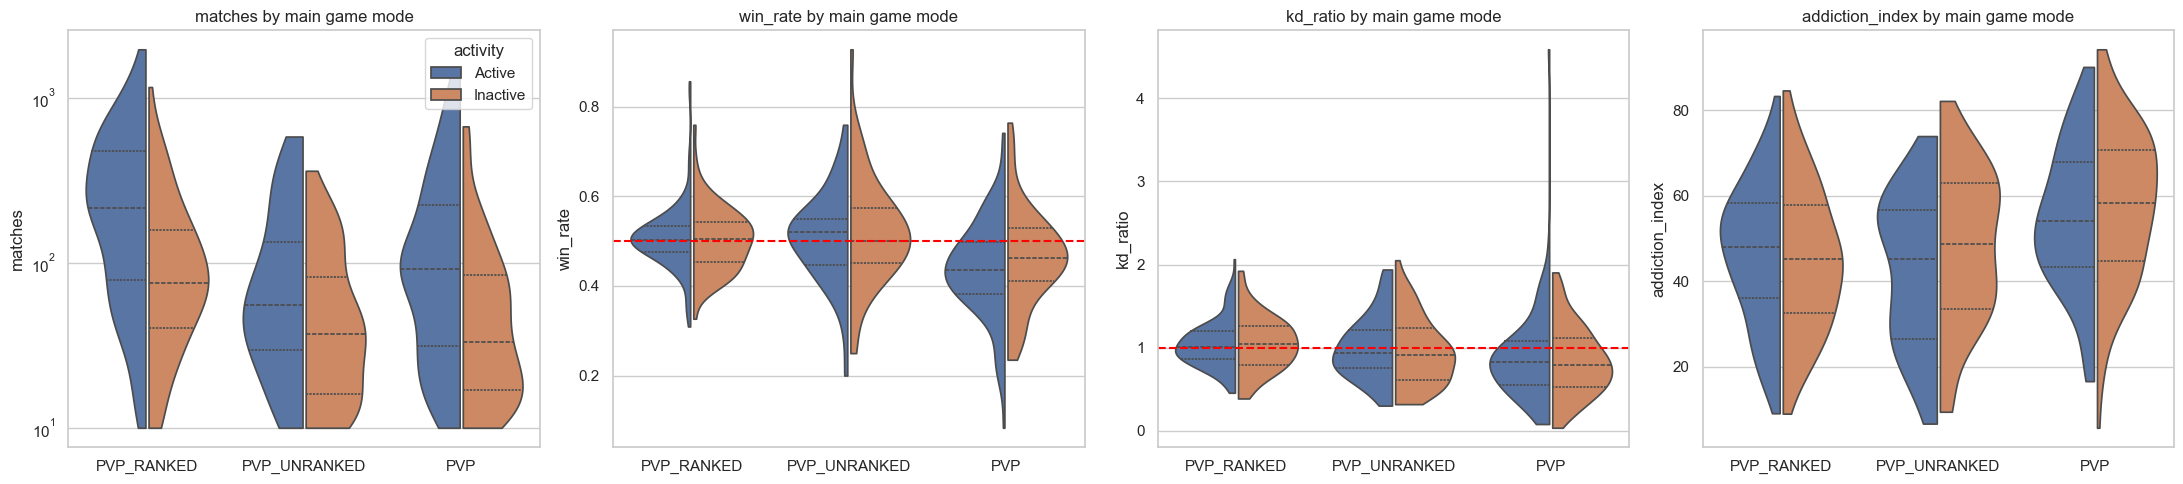

main_mode,activity,players,matches_median,win_rate_median,kd_median,addiction_median
str,str,u32,f64,f64,f64,f64
"""PVP""","""Active""",115,92.0,0.435,0.825,54.1
"""PVP""","""Inactive""",105,33.0,0.463,0.794,58.3
"""PVP_RANKED""","""Active""",144,215.0,0.502,1.014,48.0
"""PVP_RANKED""","""Inactive""",78,75.5,0.504,1.041,45.2
"""PVP_UNRANKED""","""Active""",44,55.5,0.52,0.935,45.3
"""PVP_UNRANKED""","""Inactive""",57,37.0,0.5,0.911,48.7


In [ ]:
MODE_SHARES: dict[str, str] = {'share_pvp_ranked': 'PVP_RANKED', 'share_pvp_unranked': 'PVP_UNRANKED', 'share_pvp': 'PVP'}
GAMEMODE_ORDER: list[str] = list(MODE_SHARES.values())
df_main_mode: pl.DataFrame = df_players_10.with_columns(
    pl.concat_list(list(MODE_SHARES)).list.arg_max().replace_strict(dict(enumerate(GAMEMODE_ORDER)), return_dtype=pl.String).alias('main_mode')
)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, feature, ref in zip(axes, ['matches', 'win_rate', 'kd_ratio', 'addiction_index'], [None, 0.5, 1, None]):
    sns.violinplot(
        data=df_main_mode.to_pandas(), x='main_mode', y=feature, hue='activity', order=GAMEMODE_ORDER, hue_order=HUE_ORDER,
        split=True, inner='quartile', cut=0, density_norm='width', gap=0.05, log_scale=feature == 'matches', ax=ax,
    )
    if ref is not None:
        ax.axhline(ref, color='red', linestyle='--')
    ax.set_title(feature + ' by main game mode')
    ax.set_xlabel('')
    if feature != 'matches':
        ax.get_legend().remove()
fig.tight_layout()
plt.show()

df_main_mode.group_by('main_mode', 'activity').agg(
    pl.len().alias('players'),
    pl.col('matches').median().alias('matches_median'),
    pl.col('win_rate').median().round(3).alias('win_rate_median'),
    pl.col('kd_ratio').median().round(3).alias('kd_median'),
    pl.col('addiction_index').median().round(1).alias('addiction_median'),
).sort('main_mode', 'activity')

Observation:
- Share of active players by main mode (10+ matches): **65% in `PVP_RANKED`** (144 of 222), 52% in `PVP` (115 of 220), 44% in `PVP_UNRANKED` (44 of 101).
- Active players have 1.5 to 2.8 times more matches in every mode (e.g. median 215 vs 75.5 in `PVP_RANKED`), with the same win rate and K/D (gaps below 0.03, except win rate in `PVP`: 46.3% vs 43.5%).
- Addiction index goes both ways (inactive higher in `PVP`, active higher in `PVP_RANKED`): no stable pattern.

## 7. Short profile of the two groups

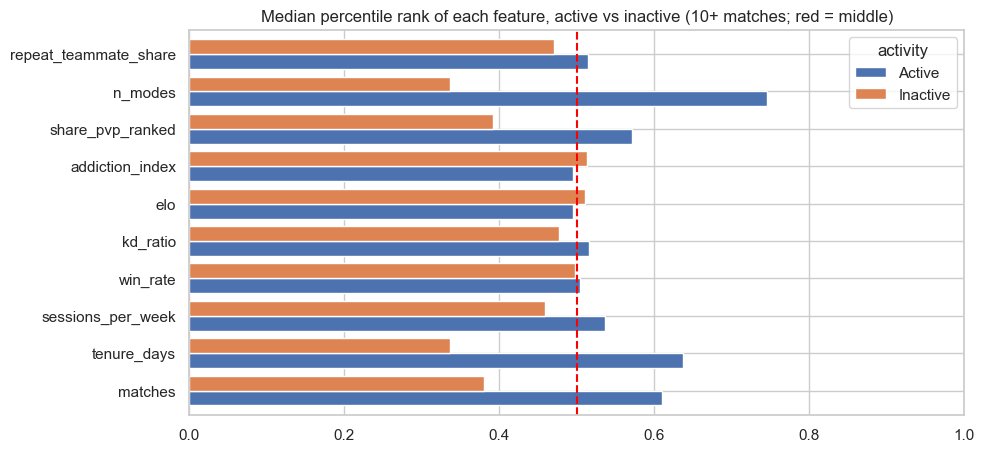

activity,matches,tenure_days,sessions_per_week,win_rate,kd_ratio,elo,addiction_index,share_pvp_ranked,n_modes,repeat_teammate_share
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Active""",110.0,250.339,2.741,0.49,0.946,987.686,50.605,0.4,3.0,0.243
"""Inactive""",50.5,81.495,2.284,0.489,0.916,989.947,51.592,0.031,2.0,0.226


In [ ]:
PROFILE = ['matches', 'tenure_days', 'sessions_per_week', 'win_rate', 'kd_ratio', 'elo', 'addiction_index', 'share_pvp_ranked', 'n_modes', 'repeat_teammate_share']
# each feature as a percentile rank over all 10+ players, so that different units share one scale
df_ranked = df_players_10.with_columns(*[(pl.col(c).rank() / pl.col(c).count()).alias(c) for c in PROFILE])
df_profile_rank = df_ranked.group_by('activity').agg(*[pl.col(c).median().alias(c) for c in PROFILE]).sort('activity').to_pandas().set_index('activity')

fig, ax = plt.subplots(figsize=(10, 5))
df_profile_rank.T.plot.barh(ax=ax, width=0.8)
ax.axvline(0.5, color='red', linestyle='--')
ax.set_xlim(0, 1)
ax.set_title('Median percentile rank of each feature, active vs inactive (10+ matches; red = middle)')
plt.show()
df_players_10.group_by('activity').agg(*[pl.col(c).median().round(3).alias(c) for c in PROFILE]).sort('activity')

Observation:
- Active players rank high on lifespan, volume, ranked share and number of modes; both groups sit at the same rank on skill and on the addiction index.
- So who stays is an **engaged, multi-mode, ranked player over a long period**, not a better or more intense player.
- Next: model churn on the first 30 days only, to separate cause from consequence.